FIGURE S3

Shahlo Solieva 

Created 08032026

RMSD to starting structure. align by framework then calculate CA RMSD.

In [1]:
import numpy as np
import mdtraj as md
import pickle
import matplotlib.pyplot as plt

# RMSD

In [2]:
def get_rmsd(sys_name, VH_resis, VL_resis,  target_chains=[0,1]):
    # Import atom indices for FR:
    fr_indices_data_path = '/mnt/pure/bowmanlab/WG-shahlo/projects/Ab_dynamics/analysis/paratope_RMSD/data/'
    fr_indices = np.load(f'{fr_indices_data_path}{sys_name}-FR-indices.npy')
    
    # Import starting pdb structure
    cluster_dir_path = f"/mnt/pure/bowmanlab/WG-shahlo/projects/Ab_dynamics/analysis/clustering/radius_15_variable/data/apo/{sys_name}/"
    pdb = md.load(f'{cluster_dir_path}prot_masses.pdb')

    # Select variable region atom indices (heavy + light chains)
    start_of_VH = VH_resis[0]
    end_of_VH   = VH_resis[1]
    start_of_VL = VL_resis[0]
    end_of_VL   = VL_resis[1]
    variable_indices = np.concatenate([pdb.topology.select(f'chainid {target_chains[0]} and residue {start_of_VH} to {end_of_VH} and name CA'),
                                       pdb.topology.select(f'chainid {target_chains[1]} and residue {start_of_VL} to {end_of_VL} and name CA')])
    print(len(variable_indices), variable_indices[0:3], variable_indices[-3:])

    # Import cluster centers:
    
    file=f"{cluster_dir_path}cluster-centers.pickle"
    with open(file, 'rb') as file:
        centers=pickle.load(file) # load in cluster centers.

    # Import eq probabilities:
    eq_probs = np.load(f'{cluster_dir_path}eq_probs_msm_100.npy')

    # RMSD, align by FR
    rmsd_values = []
    for center_ind in range(len(centers)):
        centers[center_ind].superpose(pdb, atom_indices=fr_indices)
        starting_xyz = pdb.xyz[:, variable_indices, :]
        center_xyz = centers[center_ind].xyz[0, variable_indices, :]
        rmsd = np.sqrt(np.mean(np.sum((starting_xyz - center_xyz)**2, axis=2), axis=1))
        rmsd_values.append(rmsd[0]*10) # convert nm to Angstroms
    return rmsd_values, eq_probs

In [11]:
# colors = ['#80bfff','palevioletred','pink','lavenderblush','#004080']

# 3F8

In [16]:
lineage = 'Ab3F8' # "1" "119" "1" "101"

VH_resis = ["1","119"]
VL_resis = ["1","101"]

naive_rmsd_values, naive_eq_probs   = get_rmsd('Ab3F8_naive_VC', VH_resis, VL_resis,  target_chains=[0,1])
I_rmsd_values, I_eq_probs           = get_rmsd('Ab3F8_I56S_VC', VH_resis, VL_resis,  target_chains=[0,1])
mature_rmsd_values, mature_eq_probs = get_rmsd('Ab3F8_mature_VC', VH_resis, VL_resis,  target_chains=[0,1])

220 [ 4 21 37] [4728 4742 4764]
220 [ 4 21 37] [4728 4742 4764]
220 [ 4 21 37] [4736 4750 4772]


In [18]:
print(np.max(np.concatenate([naive_rmsd_values,mature_rmsd_values,I_rmsd_values])))

3.4729063510894775


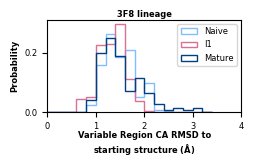

In [27]:
plt.figure(figsize=[2.5,1.2])
bins=np.arange(0,3.6,0.2)
plt.hist(naive_rmsd_values,  bins=bins,weights=naive_eq_probs,  edgecolor='#80bfff',       label='Naive', histtype='step')
plt.hist(I_rmsd_values,      bins=bins, weights=I_eq_probs,     edgecolor='palevioletred',       label='I1', histtype='step')
plt.hist(mature_rmsd_values, bins=bins, weights=mature_eq_probs,edgecolor='#004080',       label='Mature', histtype='step')
plt.xlabel('Variable Region CA RMSD to\nstarting structure ('+r'$\mathbf{\AA}$'+')',fontsize=6, weight='bold', labelpad=0)
plt.ylabel('Probability',fontsize=6, weight='bold')
plt.title('3F8 lineage', fontsize=6, weight='bold', pad=2)
plt.yticks(fontsize=6)
plt.xticks(fontsize=6)
plt.legend(fontsize=6)
plt.xlim(0,4)
plt.savefig(f"../figures/VH_VL_RMSD_to_starting_structure_{lineage}.pdf", dpi=300, bbox_inches='tight', transparent=True)
plt.show()

# PGT121

In [5]:
lineage = 'PGT121' 

sys_name = 'PGT121_naive_lambda_VC'
VH_resis = ["1","132"]
VL_resis = ["1","109"]
naive_rmsd_values, naive_eq_probs   = get_rmsd(sys_name, VH_resis, VL_resis,  target_chains=[0,1])

sys_name = 'PGT121_3H3L_VC'
VH_resis = ["1","132"]
VL_resis = ["1","112"]
I1_rmsd_values, I1_eq_probs = get_rmsd(sys_name, VH_resis, VL_resis,  target_chains=[0,1])

sys_name = 'PGT121_32H3L_VC'
VH_resis = ["1","132"]
VL_resis = ["1","112"]
I2_rmsd_values, I2_eq_probs = get_rmsd(sys_name, VH_resis, VL_resis,  target_chains=[0,1])

sys_name = 'PGT121_9H3L_VC'
VH_resis = ["1","132"]
VL_resis = ["1","112"]
I3_rmsd_values, I3_eq_probs = get_rmsd(sys_name, VH_resis, VL_resis,  target_chains=[0,1])

sys_name = 'PGT121_mature_lambda_VC'
VH_resis = ["1","132"]
VL_resis = ["1","105"]
mature_rmsd_values, mature_eq_probs = get_rmsd(sys_name, VH_resis, VL_resis,  target_chains=[0,1])

print(np.max(np.concatenate([naive_rmsd_values,I1_rmsd_values, I2_rmsd_values, I3_rmsd_values, mature_rmsd_values])))

241 [ 4 21 37] [5064 5078 5094]
244 [ 4 21 37] [5137 5151 5167]
244 [ 4 21 37] [5160 5174 5190]
244 [ 4 21 37] [5129 5143 5159]
237 [ 4 21 38] [5006 5020 5036]
5.126080513000488


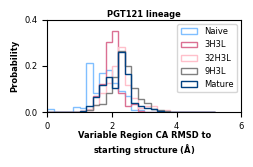

In [6]:
plt.figure(figsize=[2.5,1.2])
bins=np.arange(0,5.4,0.2)
plt.hist(naive_rmsd_values,  bins=bins,weights=naive_eq_probs,  edgecolor='#80bfff',       label='Naive', histtype='step')
plt.hist(I1_rmsd_values,  bins=bins,weights=I1_eq_probs,        edgecolor='palevioletred', label='3H3L', histtype='step')
plt.hist(I2_rmsd_values,  bins=bins,weights=I2_eq_probs,        edgecolor='pink',          label='32H3L', histtype='step')
plt.hist(I3_rmsd_values,  bins=bins,weights=I3_eq_probs,        edgecolor='gray', label='9H3L', histtype='step')
plt.hist(mature_rmsd_values, bins=bins, weights=mature_eq_probs,edgecolor='#004080',       label='Mature', histtype='step')
plt.xlabel('Variable Region CA RMSD to\nstarting structure ('+r'$\mathbf{\AA}$'+')',fontsize=6, weight='bold', labelpad=0)
plt.ylabel('Probability',fontsize=6, weight='bold')
plt.title('PGT121 lineage', fontsize=6, weight='bold', pad=2)
plt.yticks(fontsize=6)
plt.xticks(fontsize=6)
plt.legend(fontsize=6)
plt.xlim(0,6)
plt.ylim(0,0.4)
plt.savefig(f"../figures/VH_VL_RMSD_to_starting_structure_{lineage}.pdf", dpi=300, bbox_inches='tight', transparent=True)
plt.show()


# 1-18

In [3]:
lineage = '1-18' 

sys_name = 'Ab118_naive_VC'
VH_resis = ["1","125"]
VL_resis = ["1","108"]
naive_rmsd_values, naive_eq_probs   = get_rmsd(sys_name, VH_resis, VL_resis,  target_chains=[0,1])

sys_name = 'Ab118_I_VC'
VH_resis = ["1","131"]
VL_resis = ["1","108"]
I1_rmsd_values, I1_eq_probs = get_rmsd(sys_name, VH_resis, VL_resis,  target_chains=[0,1])

sys_name = 'Ab118_IAb2748_VC'
VH_resis = ["1","131"]
VL_resis = ["1","108"]
I2_rmsd_values, I2_eq_probs = get_rmsd(sys_name, VH_resis, VL_resis,  target_chains=[0,1])

sys_name = 'Ab118_IAb0923_VC'
VH_resis = ["1","131"]
VL_resis = ["1","108"]
I3_rmsd_values, I3_eq_probs = get_rmsd(sys_name, VH_resis, VL_resis,  target_chains=[0,1])

sys_name = 'Ab118_mature_VC'
VH_resis = ["1","131"]
VL_resis = ["1","108"]
mature_rmsd_values, mature_eq_probs = get_rmsd(sys_name, VH_resis, VL_resis,  target_chains=[0,1])

print(np.max(np.concatenate([naive_rmsd_values,I1_rmsd_values, I2_rmsd_values, I3_rmsd_values, mature_rmsd_values])))

233 [ 4 21 37] [4930 4945 4964]
239 [ 4 21 37] [5088 5100 5122]
239 [ 4 21 36] [5072 5084 5106]
239 [ 4 21 31] [5144 5156 5173]
239 [ 4 21 28] [5116 5128 5150]
5.745443105697632


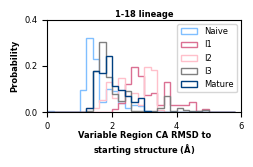

In [4]:
plt.figure(figsize=[2.5,1.2])
bins=np.arange(0,6,0.2)
plt.hist(naive_rmsd_values,  bins=bins,weights=naive_eq_probs,  edgecolor='#80bfff',       label='Naive', histtype='step')
plt.hist(I1_rmsd_values,  bins=bins,weights=I1_eq_probs,        edgecolor='palevioletred', label='I1', histtype='step')
plt.hist(I2_rmsd_values,  bins=bins,weights=I2_eq_probs,        edgecolor='pink',          label='I2', histtype='step')
plt.hist(I3_rmsd_values,  bins=bins,weights=I3_eq_probs,        edgecolor='gray', label='I3', histtype='step')
plt.hist(mature_rmsd_values, bins=bins, weights=mature_eq_probs,edgecolor='#004080',       label='Mature', histtype='step')
plt.xlabel('Variable Region CA RMSD to\nstarting structure ('+r'$\mathbf{\AA}$'+')',fontsize=6, weight='bold', labelpad=0)
plt.ylabel('Probability',fontsize=6, weight='bold')
plt.title('1-18 lineage', fontsize=6, weight='bold', pad=2)
plt.yticks(fontsize=6)
plt.xticks(fontsize=6)
plt.legend(fontsize=6)
plt.xlim(0,6)
plt.ylim(0,0.4)
plt.savefig(f"../figures/VH_VL_RMSD_to_starting_structure_{lineage}.pdf", dpi=300, bbox_inches='tight', transparent=True)
plt.show()


# EPTC112

In [35]:
lineage = 'EPTC112'

sys_name = 'EPTC112_naive_VC'
VH_resis = ["1","121"]
VL_resis = ["1","110"]
naive_rmsd_values, naive_eq_probs   = get_rmsd(sys_name, VH_resis, VL_resis,  target_chains=[0,1])

sys_name = 'EPTC112_mature_VC'
VH_resis = ["1","121"]
VL_resis = ["1","110"]
mature_rmsd_values, mature_eq_probs = get_rmsd(sys_name, VH_resis, VL_resis,  target_chains=[0,1])

print(np.max(np.concatenate([naive_rmsd_values, mature_rmsd_values])))

231 [ 4 21 37] [4834 4848 4864]
231 [ 4 21 37] [4880 4894 4910]
2.116525024175644


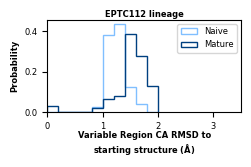

In [36]:
plt.figure(figsize=[2.5,1.2])
bins=np.arange(0,2.2,0.2)
plt.hist(naive_rmsd_values,  bins=bins,weights=naive_eq_probs,  edgecolor='#80bfff',       label='Naive', histtype='step')
plt.hist(mature_rmsd_values, bins=bins, weights=mature_eq_probs,edgecolor='#004080',       label='Mature', histtype='step')
plt.xlabel('Variable Region CA RMSD to\nstarting structure ('+r'$\mathbf{\AA}$'+')',fontsize=6, weight='bold', labelpad=0)
plt.ylabel('Probability',fontsize=6, weight='bold')
plt.title('EPTC112 lineage', fontsize=6, weight='bold', pad=2)
plt.yticks(fontsize=6)
plt.xticks(fontsize=6)
plt.legend(fontsize=6)
plt.xlim(0,3.5)
plt.savefig(f"../figures/VH_VL_RMSD_to_starting_structure_{lineage}.pdf", dpi=300, bbox_inches='tight', transparent=True)
plt.show()

# CAP256

In [7]:
lineage='CAP256'

sys_name = 'CAP256_naive_VC'
VH_resis = ["1","144"]
VL_resis = ["1","111"]
naive_rmsd_values, naive_eq_probs = get_rmsd(sys_name, VH_resis, VL_resis,  target_chains=[0,1])

sys_name = 'CAP256_mature_VC'
VH_resis = ["1","145"]
VL_resis = ["1","111"]
mature_rmsd_values, mature_eq_probs = get_rmsd(sys_name, VH_resis, VL_resis,  target_chains=[0,1])

sys_name = 'CAP256_I01_VC'
VH_resis = ["1","144"]
VL_resis = ["1","111"]
I01_rmsd_values, I01_eq_probs = get_rmsd(sys_name, VH_resis, VL_resis,  target_chains=[0,1])

sys_name = 'CAP256_I03_VC'
VH_resis = ["1","144"]
VL_resis = ["1","111"]
I03_rmsd_values, I03_eq_probs = get_rmsd(sys_name, VH_resis, VL_resis,  target_chains=[0,1])

sys_name = 'CAP256_I04_VC'
VH_resis = ["1","144"]
VL_resis = ["1","111"]
I04_rmsd_values, I04_eq_probs = get_rmsd(sys_name, VH_resis, VL_resis,  target_chains=[0,1])

sys_name = 'CAP256_I07_VC'
VH_resis = ["1","144"]
VL_resis = ["1","111"]
I07_rmsd_values, I07_eq_probs = get_rmsd(sys_name, VH_resis, VL_resis,  target_chains=[1,0])

sys_name = 'CAP256_I10_VC'
VH_resis = ["1","144"]
VL_resis = ["1","111"]
I10_rmsd_values, I10_eq_probs = get_rmsd(sys_name, VH_resis, VL_resis,  target_chains=[1,0])

print(np.max(np.concatenate([naive_rmsd_values,mature_rmsd_values,I01_rmsd_values,I03_rmsd_values,I04_rmsd_values, I07_rmsd_values, I10_rmsd_values])))


255 [ 4 21 37] [5176 5190 5206]
256 [ 4 21 37] [5289 5308 5324]
255 [ 4 19 35] [5191 5205 5221]
255 [ 4 19 35] [5294 5308 5324]
255 [ 4 19 35] [5290 5309 5325]
255 [3195 3210 3226] [1571 1585 1601]
255 [3198 3215 3225] [1575 1589 1605]
9.334112405776978


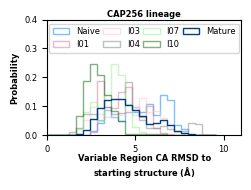

In [22]:
plt.figure(figsize=[2.5,1.5])
bins=np.arange(0,10,0.4)
plt.hist(naive_rmsd_values,  bins=bins,weights=naive_eq_probs,  edgecolor='#80bfff',       label='Naive', histtype='step')
plt.hist(I01_rmsd_values,    bins=bins, weights=I01_eq_probs,   alpha=0.5, edgecolor='palevioletred', label='I01', histtype='step')
plt.hist(I03_rmsd_values,    bins=bins, weights=I03_eq_probs,   alpha=0.5, edgecolor='pink', label='I03', histtype='step')
plt.hist(I04_rmsd_values,    bins=bins, weights=I04_eq_probs,   alpha=0.5, edgecolor='gray', label='I04', histtype='step')
plt.hist(I07_rmsd_values,    bins=bins, weights=I07_eq_probs,   alpha=0.5, edgecolor='lightgreen', label='I07', histtype='step')
plt.hist(I10_rmsd_values,    bins=bins, weights=I10_eq_probs,   alpha=0.5, edgecolor='darkgreen', label='I10', histtype='step')
plt.hist(mature_rmsd_values, bins=bins, weights=mature_eq_probs,edgecolor='#004080',       label='Mature', histtype='step')
plt.xlabel('Variable Region CA RMSD to\nstarting structure ('+r'$\mathbf{\AA}$'+')',fontsize=6, weight='bold', labelpad=0)
plt.ylabel('Probability',fontsize=6, weight='bold')
plt.title('CAP256 lineage', fontsize=6, weight='bold', pad=2)
plt.yticks(fontsize=6)
plt.xticks(fontsize=6)
plt.legend(fontsize=6, loc='upper center', ncols=4, columnspacing=0.4) 
#plt.legend(fontsize=6, loc='center left', bbox_to_anchor=(1, 0.5))
plt.xlim(0,11)
plt.ylim(0,0.4) #0.27)
plt.savefig(f"../figures/VH_VL_RMSD_to_starting_structure_{lineage}-styleB.pdf", dpi=300, bbox_inches='tight', transparent=True)
plt.show()

# CH103

In [5]:
lineage='CH103'

sys_name = 'CH103_naive_VC'
VH_resis = ["1","121"]
VL_resis = ["1","108"]
naive_rmsd_values, naive_eq_probs = get_rmsd(sys_name, VH_resis, VL_resis,  target_chains=[0,1])

sys_name = 'CH103_mature_VC'
VH_resis = ["1","121"]
VL_resis = ["1","105"]
mature_rmsd_values, mature_eq_probs = get_rmsd(sys_name, VH_resis, VL_resis,  target_chains=[0,1])

sys_name = 'CH103_I32_VC'
VH_resis = ["1","121"]
VL_resis = ["2","108"]
I32_rmsd_values, I32_eq_probs = get_rmsd(sys_name, VH_resis, VL_resis,  target_chains=[0,1])

sys_name = 'CH103_I2_VC'
VH_resis = ["1","121"]
VL_resis = ["1","108"]
I2_rmsd_values, I2_eq_probs = get_rmsd(sys_name, VH_resis, VL_resis,  target_chains=[0,1])

print(np.max(np.concatenate([naive_rmsd_values,mature_rmsd_values,I32_rmsd_values,I2_rmsd_values])))


229 [ 4 21 37] [4859 4875 4894]
226 [ 4 21 37] [4801 4817 4836]
228 [ 4 21 37] [4835 4851 4870]
229 [ 4 21 37] [4856 4872 4891]
4.57778126001358


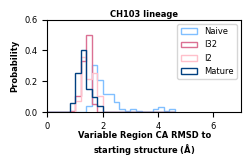

In [8]:
plt.figure(figsize=[2.5,1.2])
bins=np.arange(0,4.8,0.2)
plt.hist(naive_rmsd_values,  bins=bins,weights=naive_eq_probs,  edgecolor='#80bfff',       label='Naive', histtype='step')
plt.hist(I32_rmsd_values,  bins=bins,weights=I32_eq_probs,        edgecolor='palevioletred', label='I32', histtype='step')
plt.hist(I2_rmsd_values,  bins=bins,weights=I2_eq_probs,        edgecolor='pink',          label='I2', histtype='step')
plt.hist(mature_rmsd_values, bins=bins, weights=mature_eq_probs,edgecolor='#004080',       label='Mature', histtype='step')
plt.xlabel('Variable Region CA RMSD to\nstarting structure ('+r'$\mathbf{\AA}$'+')',fontsize=6, weight='bold', labelpad=0)
plt.ylabel('Probability',fontsize=6, weight='bold')
plt.title('CH103 lineage', fontsize=6, weight='bold', pad=2)
plt.yticks(fontsize=6)
plt.xticks(fontsize=6)
plt.legend(fontsize=6)
plt.xlim(0,7)
plt.ylim(0,0.6)
plt.savefig(f"../figures/VH_VL_RMSD_to_starting_structure_{lineage}.pdf", dpi=300, bbox_inches='tight', transparent=True)
plt.show()

# CH65

In [14]:
lineage = 'CH65'

sys_name = 'CH65_naive_VC'
VH_resis = ["1","126"]
VL_resis = ["1","108"]
naive_rmsd_values, naive_eq_probs = get_rmsd(sys_name, VH_resis, VL_resis,  target_chains=[0,1])

sys_name = 'CH65_mature_VC'
mature_rmsd_values, mature_eq_probs = get_rmsd(sys_name, VH_resis, VL_resis,  target_chains=[0,1])

sys_name = 'CH65_I2_VC'
I2_rmsd_values, I2_eq_probs = get_rmsd(sys_name, VH_resis, VL_resis,  target_chains=[0,1])

print(np.max(np.concatenate([naive_rmsd_values,mature_rmsd_values,I2_rmsd_values])))

234 [ 4 21 37] [4907 4921 4937]
234 [ 4 19 35] [4896 4910 4926]
234 [ 4 21 37] [4916 4930 4946]
3.858189284801483


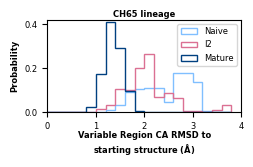

In [15]:
plt.figure(figsize=[2.5,1.2])
bins=np.arange(0,4,0.2)
plt.hist(naive_rmsd_values,  bins=bins,weights=naive_eq_probs,  edgecolor='#80bfff',       label='Naive', histtype='step')
plt.hist(I2_rmsd_values,  bins=bins,weights=I2_eq_probs,        edgecolor='palevioletred',          label='I2', histtype='step')
plt.hist(mature_rmsd_values, bins=bins, weights=mature_eq_probs,edgecolor='#004080',       label='Mature', histtype='step')
plt.xlabel('Variable Region CA RMSD to\nstarting structure ('+r'$\mathbf{\AA}$'+')',fontsize=6, weight='bold', labelpad=0)
plt.ylabel('Probability',fontsize=6, weight='bold')
plt.title('CH65 lineage', fontsize=6, weight='bold', pad=2)
plt.yticks(fontsize=6)
plt.xticks(fontsize=6)
plt.legend(fontsize=6)
plt.xlim(0,4)
plt.ylim(0,0.42)
plt.savefig(f"../figures/VH_VL_RMSD_to_starting_structure_{lineage}.pdf", dpi=300, bbox_inches='tight', transparent=True)
plt.show()